# 06 Â· Tuning P1: scoring

What [`reports/method_research.md`](../reports/method_research.md) asked to tune:
- the reference model (S4) needed 2,488 trees and had the worst log loss; early stopping on validation weeks that share card holders with training may reward recognising known people;
- dropping December 2017 gave mixed results.

**Rules, fixed before running:**
1. The test weeks (20-26) are not used for any choice. `fraud.tuning` asserts it.
2. Two rolling-origin folds: F1 trains on weeks 0-11 and validates on 12-15; F2 trains on 0-15 and validates on 16-19.
3. Inside each validation window, card holders are split in two (same split for every configuration): one half drives early stopping, the other half scores the configuration.
4. Selection metric: PR-AUC on the scoring half, averaged over the two folds. Among configurations within **0.005** of the best, the simplest wins (fewer leaves, then fewer trees).

Stage A tunes the structural choices suggested by the analysis; stage B tunes hyperparameters; the final model is then evaluated **once** on the test weeks against S4.

In [1]:
import gc
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.config import load_config
from fraud.data import ENTITY_COL, PROCESSED_DIR, TARGET, load_dataset
from fraud.evaluate import average_precision, bootstrap_ci, paired_bootstrap_diff, summarize, value_capture_at_rate
from fraud.features import add_past_features, add_row_features, feature_columns
from fraud.train import fit_lgbm, log_run, predict
from fraud.tuning import (TEST_START_WEEK, assert_no_test_weeks, evaluate_config, pick_simplest_within,
                          prepare_training, random_configs, split_fold, time_folds)

cfg = load_config("model")
SEED, N_BOOT, TOLERANCE = 0, 1000, 0.005
FIG_DIR = Path("../reports/figures")

df = add_past_features(add_row_features(load_dataset("train")))
features = feature_columns(df)
# No copy: split_fold only takes weeks before the test start and asserts it (saves ~1 GB of RAM).
tuning_df = df
folds = time_folds()
for f in folds:
    tr, es, ev = split_fold(tuning_df, f, SEED)
    print(f"{f.name}: train {len(tr):,} rows (weeks 0-{f.train_last_week}), early-stopping half {len(es):,}, scoring half {len(ev):,} "
          f"({ev[TARGET].sum()} frauds)")

F1: train 294,193 rows (weeks 0-11), early-stopping half 45,662, scoring half 46,443 (1673 frauds)


F2: train 386,298 rows (weeks 0-15), early-stopping half 41,323, scoring half 41,756 (1631 frauds)


## Stage A: early-stopping protocol Ã— training window

In [2]:
def cached_runs(path, jobs, run_one):
    """Run each job once; every result is saved immediately, so an interrupted run resumes where it stopped."""
    done = pd.read_parquet(path) if path.exists() else pd.DataFrame()
    for key, job in jobs:
        if len(done) and (done["key"] == key).any():
            continue
        row = {"key": key, **run_one(job)}
        gc.collect()
        print(row)
        done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
        done.to_parquet(path)
    return done[done["key"].isin([k for k, _ in jobs])].reset_index(drop=True)

jobs_a = [(f"{p}|{w}|{f.name}", (p, w, f)) for p in ["all", "unseen"]
          for w in ["all", "drop_weeks_0_3", "half_life_4", "half_life_8"] for f in folds]
stage_a = cached_runs(PROCESSED_DIR / "tuning_stage_a.parquet", jobs_a, lambda j: {
    "es_protocol": j[0], "window": j[1],
    **evaluate_config(tuning_df, j[2], features, cfg["lgbm"], window=j[1], es_protocol=j[0], seed=SEED)})
a = stage_a.sort_values("fold").groupby(["es_protocol", "window"]).agg(
    pr_auc=("pr_auc", "mean"), pr_auc_F1=("pr_auc", "first"), pr_auc_F2=("pr_auc", "last"),
    usd_pr_auc=("usd_pr_auc", "mean"), log_loss=("log_loss", "mean"), n_trees=("n_trees", "mean"),
).reset_index()
best_a = pick_simplest_within(a, "pr_auc", TOLERANCE, ["n_trees"])
protocol, window = a.loc[best_a, "es_protocol"], a.loc[best_a, "window"]
print(f"chosen: early stopping on '{protocol}' card holders, training window '{window}'")
a.sort_values("pr_auc", ascending=False).round(4)

chosen: early stopping on 'all' card holders, training window 'half_life_4'


,es_protocol,window,pr_auc,pr_auc_F1,pr_auc_F2,usd_pr_auc,log_loss,n_trees
2,all,half_life_4,0.6276,0.5702,0.6850,0.5453,0.1417,1432.0
3,all,half_life_8,0.6221,0.5654,0.6789,0.5513,0.1135,934.0
0,all,all,0.6210,0.5679,0.6742,0.5472,0.1468,1567.0
1,all,drop_weeks_0_3,0.5963,0.5632,0.6294,0.5214,0.1328,680.0
7,unseen,half_life_8,0.5855,0.5563,0.6146,0.5191,0.0928,54.5
6,unseen,half_life_4,0.5851,0.5486,0.6215,0.5178,0.0934,71.5
5,unseen,drop_weeks_0_3,0.5678,0.5203,0.6154,0.4948,0.0943,57.5
4,unseen,all,0.5677,0.5509,0.5845,0.5028,0.0967,78.5


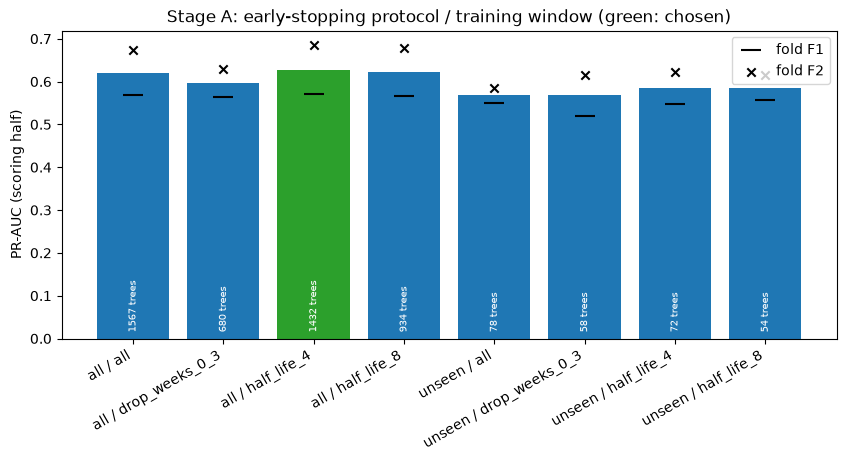

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = a["es_protocol"] + " / " + a["window"]
x = np.arange(len(a))
ax.bar(x, a["pr_auc"], color=["C2" if i == best_a else "C0" for i in a.index])
ax.scatter(x, a["pr_auc_F1"], color="k", marker="_", s=200, label="fold F1")
ax.scatter(x, a["pr_auc_F2"], color="k", marker="x", label="fold F2")
for xi, n in zip(x, a["n_trees"]):
    ax.annotate(f"{n:.0f} trees", (xi, 0.02), ha="center", fontsize=7, color="white", rotation=90)
ax.set_xticks(x, labels, rotation=30, ha="right")
ax.set(ylabel="PR-AUC (scoring half)", title="Stage A: early-stopping protocol / training window (green: chosen)")
ax.legend()
fig.savefig(FIG_DIR / "tu_stage_a.png", dpi=120, bbox_inches="tight")

## Stage B: hyperparameters (random search, chosen protocol and window)

In [4]:
space = {
    "num_leaves": [31, 63, 127, 255],
    "min_child_samples": [20, 50, 100, 200, 500],
    "colsample_bytree": [0.3, 0.5, 0.7, 0.9],
    "subsample": [0.6, 0.8, 1.0],
    "reg_lambda": [0.0, 1.0, 5.0, 20.0],
}
baseline = {k: cfg["lgbm"][k] for k in space}  # the configuration used so far
configs = [baseline] + [c for c in random_configs(space, 17, seed=SEED) if c != baseline][:16]

jobs_b = [(f"{protocol}|{window}|{i}|{f.name}", (i, overrides, f)) for i, overrides in enumerate(configs) for f in folds]
stage_b = cached_runs(PROCESSED_DIR / "tuning_stage_b.parquet", jobs_b, lambda j: {
    "config": j[0], **j[1],
    **evaluate_config(tuning_df, j[2], features, cfg["lgbm"], overrides=j[1], window=window, es_protocol=protocol, seed=SEED)})
b = stage_b.groupby("config").agg(
    **{k: (k, "first") for k in space},
    pr_auc=("pr_auc", "mean"), usd_pr_auc=("usd_pr_auc", "mean"), log_loss=("log_loss", "mean"),
    n_trees=("n_trees", "mean"), seconds=("seconds", "sum"),
)
best_b = pick_simplest_within(b, "pr_auc", TOLERANCE, ["num_leaves", "n_trees"])
chosen = {k: b.loc[best_b, k].item() if hasattr(b.loc[best_b, k], "item") else b.loc[best_b, k] for k in space}
print(f"best mean PR-AUC: config {b['pr_auc'].idxmax()} ({b['pr_auc'].max():.4f}); chosen (simplest within {TOLERANCE}): config {best_b} ({b.loc[best_b, 'pr_auc']:.4f})")
print("chosen hyperparameters:", chosen)
b.sort_values("pr_auc", ascending=False).round(4)

{'key': 'all|half_life_4|12|F2', 'config': 12, 'num_leaves': 255, 'min_child_samples': 50, 'colsample_bytree': 0.7, 'subsample': 1.0, 'reg_lambda': 5.0, 'fold': 'F2', 'pr_auc': 0.6788265478283212, 'usd_pr_auc': 0.6247864960102392, 'log_loss': 0.11197219704918687, 'n_trees': 879, 'seconds': 194}


{'key': 'all|half_life_4|13|F1', 'config': 13, 'num_leaves': 255, 'min_child_samples': 200, 'colsample_bytree': 0.7, 'subsample': 0.8, 'reg_lambda': 20.0, 'fold': 'F1', 'pr_auc': 0.5541138480705738, 'usd_pr_auc': 0.46554671883369714, 'log_loss': 0.1325161504985301, 'n_trees': 1440, 'seconds': 184}


{'key': 'all|half_life_4|13|F2', 'config': 13, 'num_leaves': 255, 'min_child_samples': 200, 'colsample_bytree': 0.7, 'subsample': 0.8, 'reg_lambda': 20.0, 'fold': 'F2', 'pr_auc': 0.6678690205856296, 'usd_pr_auc': 0.6036529565967704, 'log_loss': 0.0964372239113831, 'n_trees': 891, 'seconds': 148}


{'key': 'all|half_life_4|14|F1', 'config': 14, 'num_leaves': 31, 'min_child_samples': 100, 'colsample_bytree': 0.7, 'subsample': 1.0, 'reg_lambda': 5.0, 'fold': 'F1', 'pr_auc': 0.5575003927610525, 'usd_pr_auc': 0.46801900787415496, 'log_loss': 0.09846473237779069, 'n_trees': 549, 'seconds': 34}


{'key': 'all|half_life_4|14|F2', 'config': 14, 'num_leaves': 31, 'min_child_samples': 100, 'colsample_bytree': 0.7, 'subsample': 1.0, 'reg_lambda': 5.0, 'fold': 'F2', 'pr_auc': 0.6543740707757957, 'usd_pr_auc': 0.5891103445267794, 'log_loss': 0.08578515251069213, 'n_trees': 852, 'seconds': 56}


{'key': 'all|half_life_4|15|F1', 'config': 15, 'num_leaves': 63, 'min_child_samples': 50, 'colsample_bytree': 0.5, 'subsample': 0.8, 'reg_lambda': 5.0, 'fold': 'F1', 'pr_auc': 0.5585842639514123, 'usd_pr_auc': 0.47919783262297627, 'log_loss': 0.10019970714017917, 'n_trees': 383, 'seconds': 44}


{'key': 'all|half_life_4|15|F2', 'config': 15, 'num_leaves': 63, 'min_child_samples': 50, 'colsample_bytree': 0.5, 'subsample': 0.8, 'reg_lambda': 5.0, 'fold': 'F2', 'pr_auc': 0.6664980576142469, 'usd_pr_auc': 0.6052888118258699, 'log_loss': 0.09160537906073038, 'n_trees': 1064, 'seconds': 119}


{'key': 'all|half_life_4|16|F1', 'config': 16, 'num_leaves': 255, 'min_child_samples': 20, 'colsample_bytree': 0.9, 'subsample': 0.8, 'reg_lambda': 1.0, 'fold': 'F1', 'pr_auc': 0.5759731545984021, 'usd_pr_auc': 0.47663811296377534, 'log_loss': 0.17403087801905576, 'n_trees': 1088, 'seconds': 156}


{'key': 'all|half_life_4|16|F2', 'config': 16, 'num_leaves': 255, 'min_child_samples': 20, 'colsample_bytree': 0.9, 'subsample': 0.8, 'reg_lambda': 1.0, 'fold': 'F2', 'pr_auc': 0.6889783475880084, 'usd_pr_auc': 0.6124103765887723, 'log_loss': 0.1389553792696184, 'n_trees': 1385, 'seconds': 206}
best mean PR-AUC: config 7 (0.6363); chosen (simplest within 0.005): config 16 (0.6325)
chosen hyperparameters: {'num_leaves': 255, 'min_child_samples': 20, 'colsample_bytree': 0.9, 'subsample': 0.8, 'reg_lambda': 1.0}


,num_leaves,min_child_samples,colsample_bytree,subsample,reg_lambda,pr_auc,usd_pr_auc,log_loss,n_trees,seconds
config,,,,,,,,,,
7,255,20,0.3,1.0,0.0,0.6363,0.5543,0.2345,1299.0,339
16,255,20,0.9,0.8,1.0,0.6325,0.5445,0.1565,1236.5,362
0,127,100,0.5,0.8,1.0,0.6276,0.5453,0.1417,1432.0,399
12,255,50,0.7,1.0,5.0,0.6253,0.5500,0.1334,1042.0,408
8,127,20,0.5,0.8,1.0,0.6247,0.5460,0.1403,1341.5,379
11,255,50,0.5,1.0,20.0,0.6195,0.5435,0.1172,1212.0,418
15,63,50,0.5,0.8,5.0,0.6125,0.5422,0.0959,723.5,163
3,127,500,0.7,0.8,20.0,0.6120,0.5369,0.1039,1123.5,311
13,255,200,0.7,0.8,20.0,0.6110,0.5346,0.1145,1165.5,332


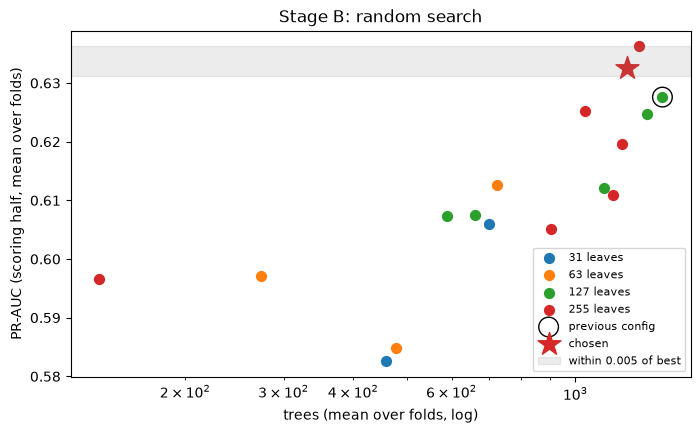

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for leaves, g in b.groupby("num_leaves"):
    ax.scatter(g["n_trees"], g["pr_auc"], label=f"{leaves} leaves", s=50)
ax.scatter(b.loc[0, "n_trees"], b.loc[0, "pr_auc"], facecolors="none", edgecolors="k", s=200, label="previous config")
ax.scatter(b.loc[best_b, "n_trees"], b.loc[best_b, "pr_auc"], marker="*", color="C3", s=300, label="chosen")
ax.axhspan(b["pr_auc"].max() - TOLERANCE, b["pr_auc"].max(), color="gray", alpha=.15, label=f"within {TOLERANCE} of best")
ax.set(xscale="log", xlabel="trees (mean over folds, log)", ylabel="PR-AUC (scoring half, mean over folds)", title="Stage B: random search")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "tu_stage_b.png", dpi=120, bbox_inches="tight")

## Final model and the one test evaluation

Chosen protocol, window and hyperparameters, learning rate 0.05, trained on weeks 0-15 with early stopping on the F2 early-stopping half. The scoring half of weeks 16-19 is kept for calibration and decisions (notebook 07). Compared once on the test weeks with S4 from notebook 03.

In [6]:
final_fold = folds[-1]
train, es, evaluation = split_fold(tuning_df, final_fold, SEED)
train, es, weight = prepare_training(train, es, window, protocol)
final_params = chosen | {"learning_rate": 0.05, "n_estimators": 10_000}
t0 = time.time()
model = fit_lgbm(train, es, features, cfg["lgbm"], seed=SEED, sample_weight=weight, overrides=final_params)
print(f"final model: {model.best_iteration_} trees, {time.time() - t0:.0f} s")

test = df[df["week"] >= TEST_START_WEEK]
s_eval, s_test = predict(model, evaluation, features), predict(model, test, features)
ref = pd.read_parquet(PROCESSED_DIR / "scores_p1.parquet").set_index("TransactionID").loc[test["TransactionID"]]
s4 = ref["S4"].to_numpy()
y, amount, groups = test[TARGET].to_numpy(), test["TransactionAmt"].to_numpy(dtype=float), test[ENTITY_COL]
seen = test[ENTITY_COL].isin(df.loc[df["week"] <= 15, ENTITY_COL].unique()).to_numpy()

rows = {}
for name, s in [("S4 (before tuning)", s4), ("tuned", s_test)]:
    ci = bootstrap_ci(y, s, groups=groups, n_boot=N_BOOT, seed=SEED)
    rows[name] = {"pr_auc": ci.estimate, "ci_low": ci.low, "ci_high": ci.high,
                  "usd_pr_auc": average_precision(y, s, amount),
                  "usd_caught_1pct": value_capture_at_rate(y, s, amount, 0.01),
                  "usd_caught_3pct": value_capture_at_rate(y, s, amount, 0.03),
                  "pr_auc_seen": average_precision(y[seen], s[seen]), "pr_auc_new": average_precision(y[~seen], s[~seen]),
                  "raw_log_loss": summarize(y, s)["log_loss"]}
rows["tuned"]["trees"], rows["S4 (before tuning)"]["trees"] = model.best_iteration_, 2488
comparison = pd.DataFrame(rows).T
display(comparison.round(4))
for label, w in [("PR-AUC", None), ("$ PR-AUC", amount)]:
    d = paired_bootstrap_diff(y, s4, s_test, groups=groups, n_boot=N_BOOT, seed=SEED, weight=w)
    print(f"tuned - S4, {label}: {d.estimate:+.4f} (95% CI {d.low:+.4f}, {d.high:+.4f})")

final model: 2314 trees, 329 s


,pr_auc,ci_low,ci_high,usd_pr_auc,usd_caught_1pct,usd_caught_3pct,pr_auc_seen,pr_auc_new,raw_log_loss,trees
S4 (before tuning),0.5337,0.5037,0.5614,0.4480,0.1629,0.4066,0.6370,0.5263,0.1710,2488.0
tuned,0.5452,0.5153,0.5740,0.4564,0.1605,0.4125,0.6677,0.5369,0.1543,2314.0


tuned - S4, PR-AUC: +0.0115 (95% CI +0.0026, +0.0200)


tuned - S4, $ PR-AUC: +0.0084 (95% CI -0.0041, +0.0210)


In [7]:
out = pd.concat([
    evaluation[["TransactionID", "week", "day", ENTITY_COL, "TransactionAmt", "ProductCD", TARGET]].assign(split="valid_scoring_half", score=s_eval),
    test[["TransactionID", "week", "day", ENTITY_COL, "TransactionAmt", "ProductCD", TARGET]].assign(split="test", score=s_test),
], ignore_index=True)
out.to_parquet(PROCESSED_DIR / "scores_tuned.parquet", index=False)
model.booster_.save_model(PROCESSED_DIR / "model_tuned.txt")
tuned = {"es_protocol": protocol, "window": window, "params": final_params, "n_trees": int(model.best_iteration_)}
(PROCESSED_DIR / "tuned_config.json").write_text(json.dumps(tuned, indent=2))
log_run("P1 tuned", {"es_protocol": protocol, "window": window, **final_params, "n_trees": model.best_iteration_},
        {k: float(v) for k, v in rows["tuned"].items()}, features, experiment="tuning")
print(tuned)

{'es_protocol': 'all', 'window': 'half_life_4', 'params': {'num_leaves': 255, 'min_child_samples': 20, 'colsample_bytree': 0.9, 'subsample': 0.8, 'reg_lambda': 1.0, 'learning_rate': 0.05, 'n_estimators': 10000}, 'n_trees': 2314}
